# MNIST-family empirical representation

The latent class distributions of an image dataset are **unknown**, so we compare independent empirical hierarchies:

- *train-to-reference:* $n$ training images per class versus a large held-out reference bank
- *reference-split:* two disjoint held-out banks of equal size, a noise floor for the reference itself.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

'TRUE'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import make_config, describe
import utils as U

# ---- Parameters ---------------------------------------------------------------
# Defaults live in config.py
OVERRIDES = {}
cfg = make_config(**OVERRIDES)
describe(cfg)

U.apply_style()
print("OT backend:", U.ot_backend())

Using config.py defaults.
OT backend: POT available; SciPy assignment used for equal-weight square problems


In [3]:
banks = U.load_image_banks(cfg)
print(f"{cfg.mnist_variant}: {len(banks['class_ids'])} classes; pixel dimension = {banks['feature_dim']}; repeats = {cfg.mnist_repeats}")
print(f"Held-out reference size = {banks['reference_n']} images per class in each of two disjoint banks")
print(f"Sample sizes: {banks['sizes'][0]}..{banks['sizes'][-1]} ({len(banks['sizes'])} values)")

Selecting image samples: 100%|██████████| 10/10 [00:00<00:00, 732.66it/s]


MNIST: 10 classes; pixel dimension = 144; repeats = 32
Held-out reference size = 446 images per class in each of two disjoint banks
Sample sizes: 4..255 (252 values)


In [4]:
df_mnist = U.run_mnist(cfg, banks)
U.save_mnist(cfg, df_mnist)

ref = df_mnist[df_mnist.experiment == "reference_split"]["distance"]
print(f"Reference/reference diagnostic: {ref.mean():.6f} +/- {1.96 * ref.std(ddof=1) / np.sqrt(len(ref)):.6f}")

MNIST reference splits: 100%|██████████| 32/32 [00:45<00:00,  1.42s/it]

Saved 8096 rows to results/mnist/mnist.csv
Reference/reference diagnostic: 0.017955 +/- 0.000177


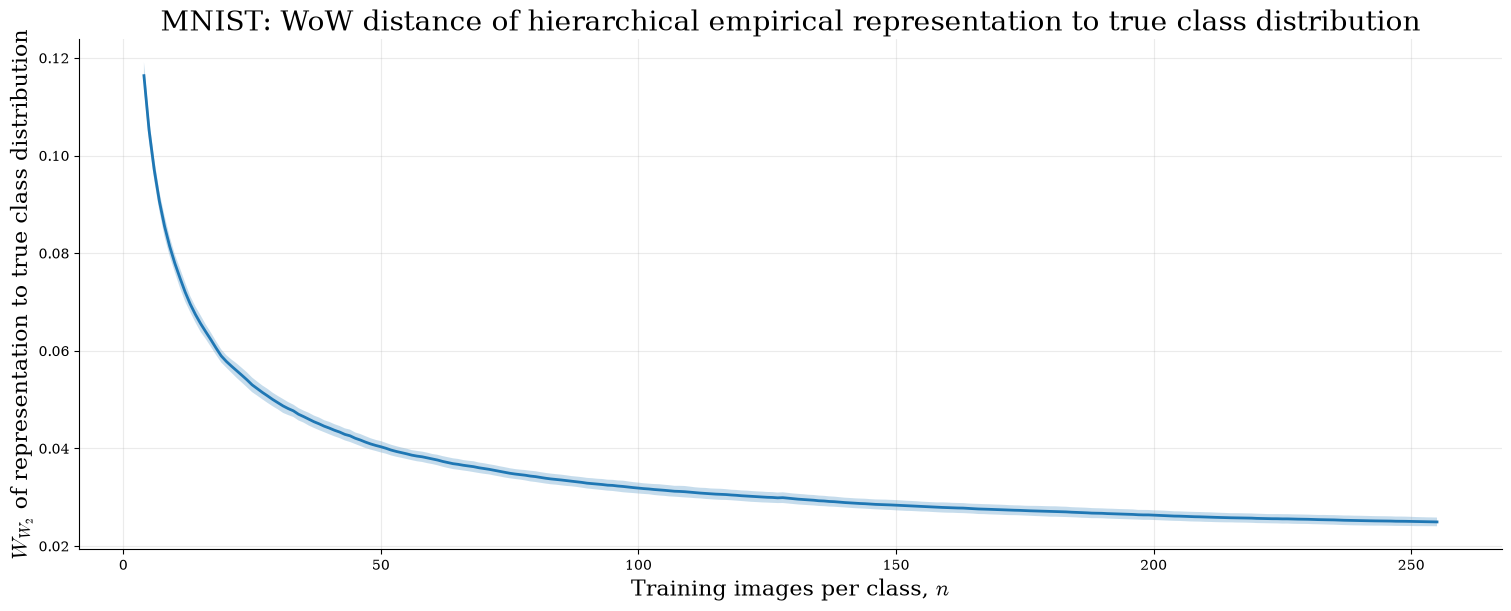

In [5]:
U.plot_mnist(df_mnist)
plt.show()

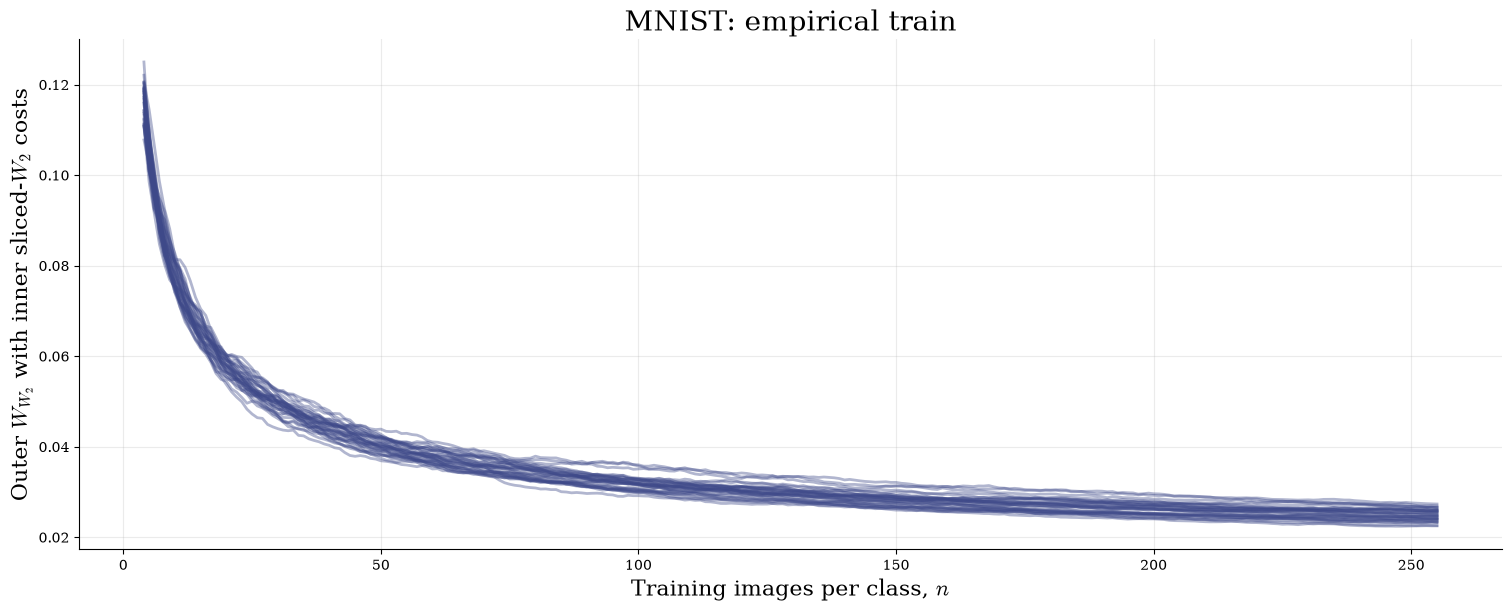

In [6]:
U.plot_mnist(df_mnist, individual=True)
plt.show()